In [1]:
# ===== 8.0  LOAD EVERYTHING NEEDED FOR TABLE 4 =====
import os, json, pickle, warnings
import numpy as np
import pandas as pd
from sklearn.metrics import (f1_score, balanced_accuracy_score, matthews_corrcoef,
                             roc_auc_score, confusion_matrix)

WORK = "/kaggle/input/datasets/keya0112/outputs-of-previous"          # or wherever you copied the previous outputs
# If the previous outputs are in an Input dataset, change the paths below accordingly, e.g.:
# PREV = "/kaggle/input/outputs-of-previous"
PREV = WORK                       # change if needed

# --- spectra + labels ---
z = np.load(f"{PREV}/spectra_trimmed.npz", allow_pickle=True)
Xt, wlt = z["Xt"], z["wlt"]
leaf_ids, y, variety = z["leaf"], z["y"], z["variety"]
chl, flav, nbi = z["chl"], z["flav"], z["nbi"]
N = len(y)

# --- classical results ---
results = pickle.load(open(f"{PREV}/results_classical.pkl", "rb"))
# reconstruct best_prep exactly as in cell 5.4
MODELS = ["PLS-DA", "LinearSVM", "RBF-SVM", "RandomForest", "LogReg-L2"]  # order is enough
best_prep = {n: max(["raw", "sg", "snv"], key=lambda p: results[(n, p)]["inner"]) for n in MODELS}

# --- neural oof predictions ---
final = pickle.load(open(f"{PREV}/nn_final.pkl", "rb"))
VARIANTS = {"M0": (False, False), "M1": (True, False), "M2": (False, True), "M3": (True, True)}
NAMES = {"M0": "1D-CNN", "M1": "CNN+Physiology", "M2": "CNN+Cultivar-GRL", "M3": "PhyloSpec-DG"}
SEEDS = [0, 1, 2, 3, 4]

oof = {vn: np.full((len(SEEDS), N), np.nan) for vn in VARIANTS}
for (vn, v), r in final.items():
    oof[vn][:, r["te"]] = r["prob"]

# --- within-domain scores for neural models ---
within_nn = json.load(open(f"{PREV}/within_nn.json"))

# --- LOCO folds + tested indices (rebuild from splits.json) ---
splits = json.load(open(f"{PREV}/splits.json"))
loco = {}
for v, d in splits["loco"].items():
    tr = np.array([np.where(leaf_ids == lid)[0][0] for lid in d["train"]])
    te = np.array([np.where(leaf_ids == lid)[0][0] for lid in d["test"]])
    loco[v] = (tr, te)
tested = np.concatenate([te for _, te in loco.values()])

# --- helper metrics (identical to Phase 4) ---
def clf_metrics(y_true, y_pred, p_fd=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    return dict(
        macro_f1 = f1_score(y_true, y_pred, average="macro", labels=[0, 1], zero_division=0),
        bal_acc  = balanced_accuracy_score(y_true, y_pred),
        mcc      = matthews_corrcoef(y_true, y_pred),
        sens     = div(tp, tp + fn),
        spec     = div(tn, tn + fp),
        prec     = div(tp, tp + fp),
        auroc    = roc_auc_score(y_true, p_fd) if p_fd is not None and len(set(y_true)) == 2 else np.nan
    )

f1m = lambda t, p: f1_score(t, p, average="macro", labels=[0, 1], zero_division=0)

def bootstrap_ci(metric_fn, y_true, pred, B=2000, seed=42):
    rng, vals = np.random.default_rng(seed), []
    for _ in range(B):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(set(y_true[i])) == 2:
            vals.append(metric_fn(y_true[i], pred[i]))
    return np.percentile(vals, [2.5, 97.5])

print("Loaded successfully:")
print(f"  classical models : {list(best_prep.keys())}")
print(f"  neural variants  : {list(NAMES.values())}")
print(f"  LOCO test leaves : {len(tested)}")
print(f"  within_nn        : {within_nn}")

Loaded successfully:
  classical models : ['PLS-DA', 'LinearSVM', 'RBF-SVM', 'RandomForest', 'LogReg-L2']
  neural variants  : ['1D-CNN', 'CNN+Physiology', 'CNN+Cultivar-GRL', 'PhyloSpec-DG']
  LOCO test leaves : 110
  within_nn        : {'M0': 0.855966995400769, 'M1': 0.8543991727561299, 'M2': 0.8538840026244318, 'M3': 0.8543991727561299}


In [2]:
# ===== PATHS =====
PREV = "/kaggle/input/datasets/keya0112/outputs-of-previous"   # read-only – only for loading
WORK = "/kaggle/working" 

In [3]:
# ===== 8.1 TABLE 4 + GENERALIZATION GAP G =====
import warnings
import numpy as np
import pandas as pd

P = {n: dict(pred=results[(n, best_prep[n])]["pred"],
             prob=results[(n, best_prep[n])]["prob"],
             within=results[(n, best_prep[n])]["within_f1"])
     for n in MODELS}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for vn in VARIANTS:
        prob = np.nanmean(oof[vn], axis=0)          # seed-averaged probability
        P[NAMES[vn]] = dict(
            pred   = (np.nan_to_num(prob) >= 0.5).astype(int),
            prob   = prob,
            within = within_nn[vn]
        )

rows = []
for n, d in P.items():
    m = clf_metrics(y[tested], d["pred"][tested], d["prob"][tested])
    lo, hi = bootstrap_ci(f1m, y[tested], d["pred"][tested])
    rows.append(dict(
        model     = n,
        within_f1 = d["within"],
        loco_f1   = m["macro_f1"],
        ci_lo     = lo,
        ci_hi     = hi,
        gap       = d["within"] - m["macro_f1"],
        bal_acc   = m["bal_acc"],
        mcc       = m["mcc"],
        auroc     = m["auroc"]
    ))

t4 = pd.DataFrame(rows).set_index("model")
display(t4.round(3))

# IMPORTANT: write only to the writable directory
t4.to_csv(f"{WORK}/table4.csv")
print("\nTable 4 saved → /kaggle/working/table4.csv")

,within_f1,loco_f1,ci_lo,ci_hi,gap,bal_acc,mcc,auroc
model,,,,,,,,
PLS-DA,0.965,0.909,0.846,0.963,0.056,0.898,0.823,0.980
LinearSVM,0.969,0.930,0.874,0.972,0.038,0.923,0.862,0.985
RBF-SVM,0.970,0.891,0.828,0.949,0.079,0.889,0.783,0.963
RandomForest,0.935,0.890,0.827,0.949,0.045,0.884,0.782,0.937
LogReg-L2,0.968,0.911,0.853,0.962,0.057,0.909,0.822,0.984
1D-CNN,0.856,0.836,0.762,0.906,0.020,0.841,0.672,0.898
CNN+Physiology,0.854,0.836,0.760,0.906,0.019,0.841,0.672,0.875
CNN+Cultivar-GRL,0.854,0.827,0.752,0.898,0.027,0.834,0.656,0.857
PhyloSpec-DG,0.854,0.836,0.760,0.906,0.019,0.841,0.672,0.886



Table 4 saved → /kaggle/working/table4.csv


Held-out cultivars (leaves, FD leaves):
  cultivar  n_leaves  n_fd
Chardonnay        23    12
 Colombard        15    10
     Duras        12     9
       Fer        15    10
     Gamay        30    19
    Mauzac        15    10

Accuracy on each held-out cultivar:


model,PLS-DA,LinearSVM,RBF-SVM,RandomForest,LogReg-L2,1D-CNN,CNN+Physiology,CNN+Cultivar-GRL,PhyloSpec-DG
cultivar,,,,,,,,,
Chardonnay,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
Colombard,0.933,0.933,0.933,0.933,0.933,1.000,1.000,1.000,1.000
Duras,1.000,1.000,1.000,0.917,1.000,0.917,0.833,0.917,0.833
Fer,0.933,1.000,1.000,1.000,1.000,0.467,0.400,0.467,0.400
Gamay,0.767,0.833,0.800,0.800,0.833,0.800,0.800,0.800,0.800
Mauzac,1.000,0.933,0.733,0.800,0.800,0.867,1.000,0.800,1.000



Macro-F1 on each held-out cultivar (NaN = cultivar has only one class):


model,PLS-DA,LinearSVM,RBF-SVM,RandomForest,LogReg-L2,1D-CNN,CNN+Physiology,CNN+Cultivar-GRL,PhyloSpec-DG
cultivar,,,,,,,,,
Chardonnay,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
Colombard,0.928,0.928,0.928,0.928,0.928,1.000,1.000,1.000,1.000
Duras,1.000,1.000,1.000,0.874,1.000,0.874,0.778,0.874,0.778
Fer,0.928,1.000,1.000,1.000,1.000,0.444,0.354,0.444,0.354
Gamay,0.689,0.795,0.744,0.744,0.795,0.744,0.744,0.744,0.744
Mauzac,1.000,0.928,0.732,0.796,0.796,0.861,1.000,0.796,1.000



Stability across cultivars:


,mean_over_cultivars_acc,worst_cultivar_acc,worst_cultivar,sd_over_cultivars_acc
model,,,,
PLS-DA,0.939,0.767,Gamay,0.090
LinearSVM,0.950,0.833,Gamay,0.066
RBF-SVM,0.911,0.733,Mauzac,0.117
RandomForest,0.908,0.800,Gamay,0.091
LogReg-L2,0.928,0.800,Mauzac,0.090
1D-CNN,0.842,0.467,Fer,0.199
CNN+Physiology,0.839,0.400,Fer,0.233
CNN+Cultivar-GRL,0.831,0.467,Fer,0.200
PhyloSpec-DG,0.839,0.400,Fer,0.233


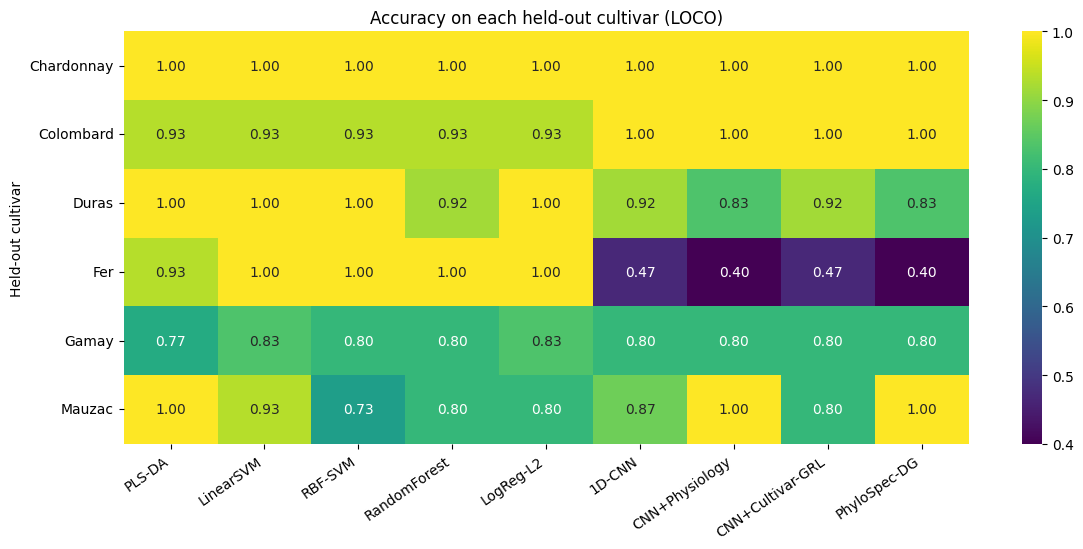

In [4]:
# ===== 8.2 PER-CULTIVAR LOCO RESULTS  (RQ1) =====
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
OUT = "/kaggle/working"                       # always write here (input folder is read-only)
os.makedirs(OUT, exist_ok=True)
model_order = list(P.keys())

rows = []
for v, (tr, te) in loco.items():
    yt = y[te]
    for n in model_order:
        pr = P[n]["pred"][te]
        rows.append(dict(cultivar=v, model=n, n_leaves=len(te), n_fd=int(yt.sum()),
                         accuracy=float((pr == yt).mean()),
                         macro_f1=f1m(yt, pr) if len(set(yt)) == 2 else np.nan))
per_cv = pd.DataFrame(rows)
per_cv.to_csv(f"{OUT}/table_per_cultivar.csv", index=False)

print("Held-out cultivars (leaves, FD leaves):")
print(per_cv.drop_duplicates("cultivar")[["cultivar", "n_leaves", "n_fd"]].to_string(index=False))

acc_tab = per_cv.pivot(index="cultivar", columns="model", values="accuracy")[model_order]
f1_tab  = per_cv.pivot(index="cultivar", columns="model", values="macro_f1")[model_order]
print("\nAccuracy on each held-out cultivar:"); display(acc_tab.round(3))
print("\nMacro-F1 on each held-out cultivar (NaN = cultivar has only one class):"); display(f1_tab.round(3))

summ = pd.DataFrame({
    "mean_over_cultivars_acc": acc_tab.mean(),
    "worst_cultivar_acc":      acc_tab.min(),
    "worst_cultivar":          acc_tab.idxmin(),
    "sd_over_cultivars_acc":   acc_tab.std(),
})
print("\nStability across cultivars:"); display(summ.round(3))
summ.to_csv(f"{OUT}/table_cultivar_stability.csv")

plt.figure(figsize=(1.0 * len(model_order) + 3, 0.6 * len(acc_tab) + 2))
sns.heatmap(acc_tab, annot=True, fmt=".2f", cmap="viridis", vmin=0.4, vmax=1)
plt.title("Accuracy on each held-out cultivar (LOCO)"); plt.xlabel(""); plt.ylabel("Held-out cultivar")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_per_cultivar_accuracy.png", dpi=300); plt.show()

,within_f1,loco_f1,ci_lo,ci_hi,gap,gap_ci_lo,gap_ci_hi,loco_CI_excludes_within
model,,,,,,,,
PLS-DA,0.965,0.909,0.846,0.963,0.056,0.002,0.119,True
LinearSVM,0.969,0.930,0.874,0.972,0.038,-0.003,0.094,False
RBF-SVM,0.970,0.891,0.828,0.949,0.079,0.021,0.142,True
RandomForest,0.935,0.890,0.827,0.949,0.045,-0.014,0.108,False
LogReg-L2,0.968,0.911,0.853,0.962,0.057,0.007,0.116,True
1D-CNN,0.856,0.836,0.762,0.906,0.020,-0.050,0.094,False
CNN+Physiology,0.854,0.836,0.760,0.906,0.019,-0.052,0.094,False
CNN+Cultivar-GRL,0.854,0.827,0.752,0.898,0.027,-0.044,0.102,False
PhyloSpec-DG,0.854,0.836,0.760,0.906,0.019,-0.052,0.094,False



Best classical = LinearSVM | best neural = 1D-CNN


,A,B,F1_A_minus_B,ci_lo,ci_hi,A_right_B_wrong,A_wrong_B_right,mcnemar_p
0,LinearSVM,1D-CNN,0.095,0.028,0.164,12,2,0.013
1,LinearSVM,PLS-DA,0.021,-0.018,0.063,3,1,0.625
2,LinearSVM,RBF-SVM,0.038,-0.006,0.089,5,1,0.219
3,LinearSVM,RandomForest,0.040,-0.003,0.092,5,1,0.219
4,LinearSVM,LogReg-L2,0.019,-0.021,0.060,3,1,0.625


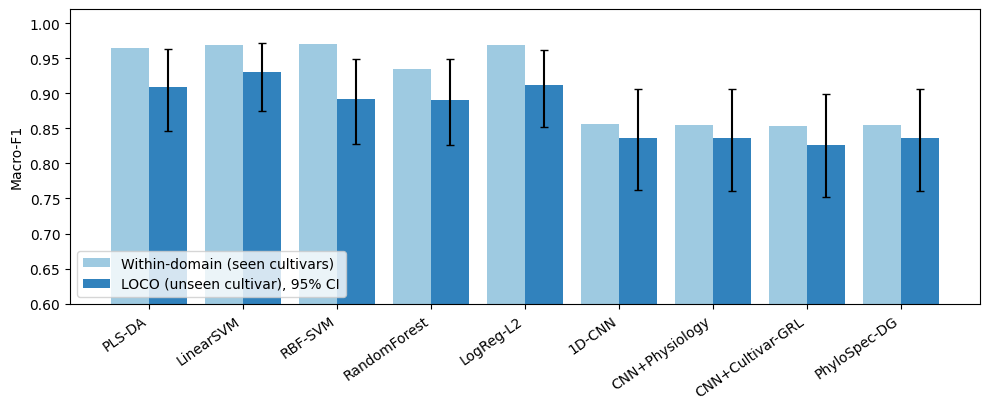

In [5]:
# ===== 8.3 RQ1: DOES AN UNSEEN CULTIVAR HURT?  within-domain vs LOCO + model comparison =====
from scipy.stats import binomtest

rq1 = t4[["within_f1", "loco_f1", "ci_lo", "ci_hi", "gap"]].copy()
# CI of the gap = within - LOCO CI (only LOCO uncertainty; within-domain is a single CV estimate)
rq1["gap_ci_lo"] = rq1["within_f1"] - rq1["ci_hi"]
rq1["gap_ci_hi"] = rq1["within_f1"] - rq1["ci_lo"]
rq1["loco_CI_excludes_within"] = rq1["within_f1"] > rq1["ci_hi"]     # True = clear drop on unseen cultivars
display(rq1.round(3))
rq1.to_csv(f"{OUT}/table_rq1_gap.csv")

def paired_boot_diff(pa, pb, yy, B=2000, seed=42):
    rng, d = np.random.default_rng(seed), []
    for _ in range(B):
        i = rng.integers(0, len(yy), len(yy))
        if len(set(yy[i])) == 2:
            d.append(f1m(yy[i], pa[i]) - f1m(yy[i], pb[i]))
    d = np.array(d)
    return float(d.mean()), *np.percentile(d, [2.5, 97.5])

def mcnemar_exact(pa, pb, yy):
    ca, cb = (pa == yy), (pb == yy)
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())      # A right/B wrong ; A wrong/B right
    return b, c, (binomtest(b, b + c, 0.5).pvalue if b + c else 1.0)

classical_names = list(MODELS)
neural_names    = [NAMES[v] for v in VARIANTS]
best_c = t4.loc[classical_names, "loco_f1"].idxmax()
best_n = t4.loc[neural_names,    "loco_f1"].idxmax()
yy = y[tested]

rows = []
for a, b in [(best_c, best_n)] + [(best_c, m) for m in classical_names if m != best_c]:
    d, lo, hi = paired_boot_diff(P[a]["pred"][tested], P[b]["pred"][tested], yy)
    nb, nc, p = mcnemar_exact(P[a]["pred"][tested], P[b]["pred"][tested], yy)
    rows.append(dict(A=a, B=b, F1_A_minus_B=d, ci_lo=lo, ci_hi=hi,
                     A_right_B_wrong=nb, A_wrong_B_right=nc, mcnemar_p=p))
cmp1 = pd.DataFrame(rows)
print(f"\nBest classical = {best_c} | best neural = {best_n}")
display(cmp1.round(3))
cmp1.to_csv(f"{OUT}/table_rq1_model_comparison.csv", index=False)

# --- figure: within-domain vs LOCO ---
order = list(t4.index)
x = np.arange(len(order))
plt.figure(figsize=(10, 4.2))
plt.bar(x - 0.2, t4["within_f1"], 0.4, label="Within-domain (seen cultivars)", color="#9ecae1")
err = np.vstack([t4["loco_f1"] - t4["ci_lo"], t4["ci_hi"] - t4["loco_f1"]])
plt.bar(x + 0.2, t4["loco_f1"], 0.4, yerr=err, capsize=3, label="LOCO (unseen cultivar), 95% CI", color="#3182bd")
plt.xticks(x, order, rotation=35, ha="right"); plt.ylabel("Macro-F1"); plt.ylim(0.6, 1.02)
plt.legend(loc="lower left"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_rq1_within_vs_loco.png", dpi=300); plt.show()

Keys stored per fold in nn_final: ['te', 'tr', 'prob', 'phys', 'epochs', 'z']

            1D-CNN vs CNN+Physiology     max|dp|=0.2472  corr=0.9226  leaves whose class differs=4/110
            1D-CNN vs CNN+Cultivar-GRL   max|dp|=0.1527  corr=0.9534  leaves whose class differs=1/110
            1D-CNN vs PhyloSpec-DG       max|dp|=0.2469  corr=0.9320  leaves whose class differs=4/110
    CNN+Physiology vs PhyloSpec-DG       max|dp|=0.0620  corr=0.9961  leaves whose class differs=0/110

Reading this: if max|dp| is ~0 and no class differs, the extra heads probably had no effect
(e.g. loss weight too small, flag not wired, or the same seed gives the same solution).
Check that before concluding that physiology 'does not help'.

Per-seed LOCO macro-F1 (neural):


/tmp/ipykernel_50/2128107759.py:5: RuntimeWarning: Mean of empty slice
  pa = np.nanmean(oof[a], axis=0)[tested]
/tmp/ipykernel_50/2128107759.py:6: RuntimeWarning: Mean of empty slice
  pb = np.nanmean(oof[b], axis=0)[tested]


,1D-CNN,CNN+Physiology,CNN+Cultivar-GRL,PhyloSpec-DG
seed0,0.836,0.793,0.732,0.793
seed1,0.853,0.725,0.654,0.775
seed2,0.671,0.618,0.599,0.549
seed3,0.785,0.802,0.785,0.802
seed4,0.834,0.779,0.834,0.790


mean +/- sd over seeds:


,1D-CNN,CNN+Physiology,CNN+Cultivar-GRL,PhyloSpec-DG
mean,0.796,0.744,0.721,0.742
std,0.074,0.076,0.095,0.108



RQ2 paired comparisons (positive = A better than B):


,comparison,A,B,F1_A_minus_B,ci_lo,ci_hi,seeds_A_better,seeds_total,A_right_B_wrong,A_wrong_B_right,mcnemar_p
0,physiology alone vs stress-only,CNN+Physiology,1D-CNN,-0.000,-0.036,0.036,1,5,2,2,1.0
1,physiology added on top of GRL,PhyloSpec-DG,CNN+Cultivar-GRL,0.009,-0.028,0.046,3,5,3,2,1.0
2,full model vs stress-only,PhyloSpec-DG,1D-CNN,-0.000,-0.036,0.036,1,5,2,2,1.0
3,cultivar-GRL alone vs stress-only,CNN+Cultivar-GRL,1D-CNN,-0.009,-0.027,0.000,0,5,0,1,1.0



Per-cultivar accuracy change (A - B):


comparison,cultivar-GRL alone vs stress-only,full model vs stress-only,physiology added on top of GRL,physiology alone vs stress-only
cultivar,,,,
Chardonnay,0.000,0.000,0.000,0.000
Colombard,0.000,0.000,0.000,0.000
Duras,0.000,-0.083,-0.083,-0.083
Fer,0.000,-0.067,-0.067,-0.067
Gamay,0.000,0.000,0.000,0.000
Mauzac,-0.067,0.133,0.200,0.133


cultivars improved / worse:


,improved,worse,equal
comparison,,,
cultivar-GRL alone vs stress-only,0,1,5
full model vs stress-only,1,2,3
physiology added on top of GRL,1,2,3
physiology alone vs stress-only,1,2,3


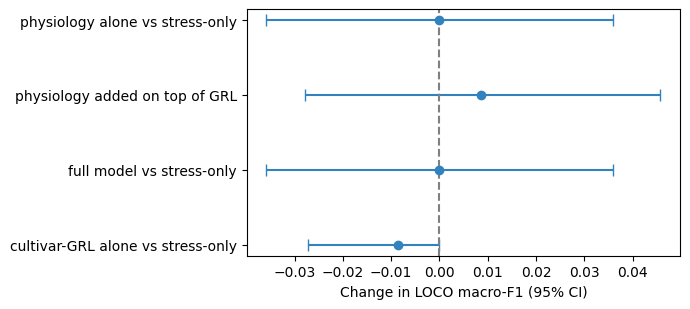

In [6]:
# ===== 8.4 RQ2 (a): SANITY CHECK - did physiology / GRL actually change the neural models? =====
print("Keys stored per fold in nn_final:", list(next(iter(final.values())).keys()))
print()
for a, b in [("M0", "M1"), ("M0", "M2"), ("M0", "M3"), ("M1", "M3")]:
    pa = np.nanmean(oof[a], axis=0)[tested]
    pb = np.nanmean(oof[b], axis=0)[tested]
    print(f"{NAMES[a]:>18s} vs {NAMES[b]:<18s} "
          f"max|dp|={np.abs(pa - pb).max():.4f}  corr={np.corrcoef(pa, pb)[0, 1]:.4f}  "
          f"leaves whose class differs={int(((pa >= .5) != (pb >= .5)).sum())}/{len(tested)}")
print("""
Reading this: if max|dp| is ~0 and no class differs, the extra heads probably had no effect
(e.g. loss weight too small, flag not wired, or the same seed gives the same solution).
Check that before concluding that physiology 'does not help'.""")

# ===== 8.4 RQ2 (b): PAIRED COMPARISONS ON UNSEEN CULTIVARS =====
def seed_f1(vn, s):
    pr = (np.nan_to_num(oof[vn][s]) >= 0.5).astype(int)
    return f1m(yy, pr[tested])

seed_tab = pd.DataFrame({NAMES[v]: [seed_f1(v, s) for s in range(len(SEEDS))] for v in VARIANTS},
                        index=[f"seed{s}" for s in SEEDS])
print("\nPer-seed LOCO macro-F1 (neural):"); display(seed_tab.round(3))
print("mean +/- sd over seeds:"); display(seed_tab.agg(["mean", "std"]).round(3))

comparisons = [("M1", "M0", "physiology alone vs stress-only"),
               ("M3", "M2", "physiology added on top of GRL"),
               ("M3", "M0", "full model vs stress-only"),
               ("M2", "M0", "cultivar-GRL alone vs stress-only")]
rows, cv_rows = [], []
for a, b, why in comparisons:
    A, B = NAMES[a], NAMES[b]
    d, lo, hi = paired_boot_diff(P[A]["pred"][tested], P[B]["pred"][tested], yy)
    nb, nc, p = mcnemar_exact(P[A]["pred"][tested], P[B]["pred"][tested], yy)
    sd = seed_tab[A] - seed_tab[B]
    rows.append(dict(comparison=why, A=A, B=B, F1_A_minus_B=d, ci_lo=lo, ci_hi=hi,
                     seeds_A_better=int((sd > 0).sum()), seeds_total=len(sd),
                     A_right_B_wrong=nb, A_wrong_B_right=nc, mcnemar_p=p))
    for v, (tr, te) in loco.items():
        cv_rows.append(dict(comparison=why, cultivar=v,
                            acc_diff=float((P[A]["pred"][te] == y[te]).mean() - (P[B]["pred"][te] == y[te]).mean())))
rq2 = pd.DataFrame(rows)
print("\nRQ2 paired comparisons (positive = A better than B):"); display(rq2.round(3))
rq2.to_csv(f"{OUT}/table_rq2_paired.csv", index=False)

cvd = pd.DataFrame(cv_rows).pivot(index="cultivar", columns="comparison", values="acc_diff")
print("\nPer-cultivar accuracy change (A - B):"); display(cvd.round(3))
print("cultivars improved / worse:")
display(pd.DataFrame({"improved": (cvd > 0).sum(), "worse": (cvd < 0).sum(), "equal": (cvd == 0).sum()}))
cvd.to_csv(f"{OUT}/table_rq2_per_cultivar.csv")

# --- forest plot ---
plt.figure(figsize=(7, 3.2))
ypos = np.arange(len(rq2))[::-1]
plt.errorbar(rq2["F1_A_minus_B"], ypos,
             xerr=[rq2["F1_A_minus_B"] - rq2["ci_lo"], rq2["ci_hi"] - rq2["F1_A_minus_B"]],
             fmt="o", capsize=4, color="#3182bd")
plt.axvline(0, color="gray", ls="--")
plt.yticks(ypos, rq2["comparison"]); plt.xlabel("Change in LOCO macro-F1 (95% CI)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_rq2_forest.png", dpi=300); plt.show()

In [7]:
# ===== 8.5 RQ2 (c): IS PHYSIOLOGY A USEFUL, TRANSFERABLE SIGNAL? =====
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

traits = {"chlorophyll": chl, "flavonol": flav, "NBI": nbi}

# (1) Does each trait on its own separate Healthy from FD?  (AUROC; 0.5 = no information)
rows = []
for name, t in traits.items():
    ok = np.isfinite(t)
    auc = roc_auc_score(y[ok], t[ok])
    row = dict(trait=name, n=int(ok.sum()), pooled_AUROC=auc,
               direction="higher in FD" if auc > 0.5 else "lower in FD")
    for v, (tr, te) in loco.items():
        m = te[np.isfinite(t[te])]
        row[v] = roc_auc_score(y[m], t[m]) if len(set(y[m])) == 2 else np.nan
    rows.append(row)
trait_auc = pd.DataFrame(rows).set_index("trait")
print("Trait-only AUROC for FD vs Healthy (pooled, then within each cultivar):")
display(trait_auc.round(3)); trait_auc.to_csv(f"{OUT}/table_trait_auroc.csv")

# (2) Can the SPECTRUM predict each trait on an UNSEEN cultivar?  (PLS, leave-one-cultivar-out)
N_COMP = 8
rows, trait_pred = [], {}
for name, t in traits.items():
    pt = np.full(N, np.nan)
    for v, (tr, te) in loco.items():
        mtr = tr[np.isfinite(t[tr])]
        if len(mtr) < 15:
            continue
        sc = StandardScaler().fit(Xt[mtr])
        pls = PLSRegression(n_components=min(N_COMP, len(mtr) - 1)).fit(sc.transform(Xt[mtr]), t[mtr])
        pt[te] = pls.predict(sc.transform(Xt[te])).ravel()
    trait_pred[name] = pt
    ok = np.isfinite(pt) & np.isfinite(t)
    row = dict(trait=name, pooled_R2=r2_score(t[ok], pt[ok]), pooled_MAE=mean_absolute_error(t[ok], pt[ok]))
    for v, (tr, te) in loco.items():
        m = te[np.isfinite(pt[te]) & np.isfinite(t[te])]
        row[v] = r2_score(t[m], pt[m]) if len(m) >= 5 else np.nan
    rows.append(row)
trait_r2 = pd.DataFrame(rows).set_index("trait")
print("\nLOCO R2 for predicting each trait from the spectrum (PLS, %d components):" % N_COMP)
display(trait_r2.round(3)); trait_r2.to_csv(f"{OUT}/table_trait_prediction_loco.csv")

# (3) Did the neural models save their own physiology predictions?
r0 = next(iter(final.values()))
phys_keys = [k for k in r0 if "phys" in str(k).lower() or "aux" in str(k).lower()]
print("\nPhysiology-related keys saved in nn_final:", phys_keys if phys_keys else "none")
print("(If none: the network's own physiology predictions were not saved; "
      "the PLS result above is the stand-in for 'is the auxiliary target learnable across cultivars'.)")

Trait-only AUROC for FD vs Healthy (pooled, then within each cultivar):


,n,pooled_AUROC,direction,Chardonnay,Colombard,Duras,Fer,Gamay,Mauzac
trait,,,,,,,,,
chlorophyll,120,0.038,lower in FD,0.000,0.02,0.000,0.0,0.077,0.00
flavonol,120,0.657,higher in FD,0.795,0.46,0.556,1.0,0.656,0.68
NBI,120,0.045,lower in FD,0.000,0.06,0.037,0.0,0.029,0.00



LOCO R2 for predicting each trait from the spectrum (PLS, 8 components):


,pooled_R2,pooled_MAE,Chardonnay,Colombard,Duras,Fer,Gamay,Mauzac
trait,,,,,,,,
chlorophyll,0.914,2.204,0.918,0.846,0.956,0.748,0.895,0.944
flavonol,-0.522,0.461,-3.431,-0.103,-0.307,-0.362,-0.202,-1.522
NBI,0.838,1.057,0.922,0.614,0.772,0.766,0.673,0.733



Physiology-related keys saved in nn_final: ['phys']
(If none: the network's own physiology predictions were not saved; the PLS result above is the stand-in for 'is the auxiliary target learnable across cultivars'.)


In [8]:
# ===== 8.6 FINAL SUMMARY TABLE FOR THE PAPER =====
final_tab = t4.copy()
final_tab["family"] = ["classical"] * len(MODELS) + ["neural"] * len(VARIANTS)
final_tab["loco_f1_95CI"] = [f"{r.loco_f1:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]" for r in final_tab.itertuples()]
final_tab = final_tab[["family", "within_f1", "loco_f1_95CI", "gap", "bal_acc", "mcc", "auroc"]]
display(final_tab.round(3))
final_tab.to_csv(f"{OUT}/table_final_summary.csv")

print("\nFiles written to", OUT)
for f in sorted(os.listdir(OUT)):
    if f.startswith(("table", "fig")):
        print("  ", f)

,family,within_f1,loco_f1_95CI,gap,bal_acc,mcc,auroc
model,,,,,,,
PLS-DA,classical,0.965,"0.909 [0.846, 0.963]",0.056,0.898,0.823,0.980
LinearSVM,classical,0.969,"0.930 [0.874, 0.972]",0.038,0.923,0.862,0.985
RBF-SVM,classical,0.970,"0.891 [0.828, 0.949]",0.079,0.889,0.783,0.963
RandomForest,classical,0.935,"0.890 [0.827, 0.949]",0.045,0.884,0.782,0.937
LogReg-L2,classical,0.968,"0.911 [0.853, 0.962]",0.057,0.909,0.822,0.984
1D-CNN,neural,0.856,"0.836 [0.762, 0.906]",0.020,0.841,0.672,0.898
CNN+Physiology,neural,0.854,"0.836 [0.760, 0.906]",0.019,0.841,0.672,0.875
CNN+Cultivar-GRL,neural,0.854,"0.827 [0.752, 0.898]",0.027,0.834,0.656,0.857
PhyloSpec-DG,neural,0.854,"0.836 [0.760, 0.906]",0.019,0.841,0.672,0.886



Files written to /kaggle/working
   fig_per_cultivar_accuracy.png
   fig_rq1_within_vs_loco.png
   fig_rq2_forest.png
   table4.csv
   table_cultivar_stability.csv
   table_final_summary.csv
   table_per_cultivar.csv
   table_rq1_gap.csv
   table_rq1_model_comparison.csv
   table_rq2_paired.csv
   table_rq2_per_cultivar.csv
   table_trait_auroc.csv
   table_trait_prediction_loco.csv
